# Example 01: NGA-West2 models for a scenario

The NGA-West2 ground-motion models (Abrahamson et al., 2014; Boore et al., 2014; Campbell and Bozorgnia, 2014; Chiou and Youngs, 2014; Idriss, 2014) predict the response spectrum of shallow crustal earthquakes in active regions. All of them take a `Scenario` and expose `periods`, `spec_accels` (median, in g) and `ln_stds`. This example computes the spectra for one scenario and shows how the models scale with magnitude, distance and $V_{s30}$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pygmm

%matplotlib inline

## One scenario

A $M_w$ 6.5 strike-slip earthquake with a vertical fault, 20 km from the site (rupture and Joyner-Boore distance), on rock with $V_{s30}$ = 760 m/s.

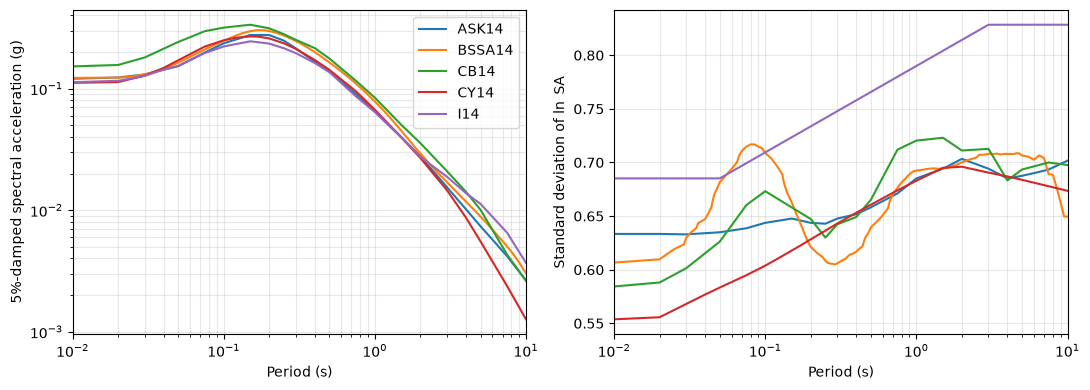

In [2]:
scenario = pygmm.Scenario(
    mag=6.5,
    dist_rup=20.0,
    dist_jb=20.0,
    dist_x=20.0,
    dip=90.0,
    mechanism="SS",
    v_s30=760.0,
)

classes = [
    pygmm.AbrahamsonSilvaKamai2014,
    pygmm.BooreStewartSeyhanAtkinson2014,
    pygmm.CampbellBozorgnia2014,
    pygmm.ChiouYoungs2014,
    pygmm.Idriss2014,
]
models = {cls.ABBREV: cls(scenario) for cls in classes}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for i, (abbrev, m) in enumerate(models.items()):
    (line,) = axes[0].plot(m.periods, m.spec_accels, label=abbrev)
    axes[1].plot(m.periods, m.ln_stds, color=line.get_color(), label=abbrev)
axes[0].set(
    xscale="log",
    yscale="log",
    xlim=(0.01, 10),
    ylabel="5%-damped spectral acceleration (g)",
)
axes[1].set(xscale="log", xlim=(0.01, 10), ylabel="Standard deviation of $\\ln$ SA")
for ax in axes:
    ax.set_xlabel("Period (s)")
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend()
fig.tight_layout()

In [3]:
periods = [0.2, 1.0, 3.0]
rows = {
    abbrev: {
        "PGA (g)": m.pga,
        **{f"SA({t} s) (g)": m.interp_spec_accels([t])[0] for t in periods},
        "sigma(1 s)": m.interp_ln_stds([1.0])[0],
    }
    for abbrev, m in models.items()
}
pd.DataFrame(rows).T.round(3)

,PGA (g),SA(0.2 s) (g),SA(1.0 s) (g),SA(3.0 s) (g),sigma(1 s)
ASK14,0.121,0.275,0.065,0.015,0.685
BSSA14,0.122,0.297,0.078,0.017,0.692
CB14,0.150,0.313,0.084,0.021,0.720
CY14,0.111,0.258,0.067,0.015,0.683
I14,0.113,0.234,0.064,0.019,0.790


## Scaling

The scenario is changed with `Scenario.copy_with`, and the 1 s spectral acceleration of each model is plotted against magnitude, distance and $V_{s30}$ with the other parameters of the scenario above fixed. (The distances $R_{rup}$, $R_{JB}$ and $R_x$ are the same for a vertical fault.)

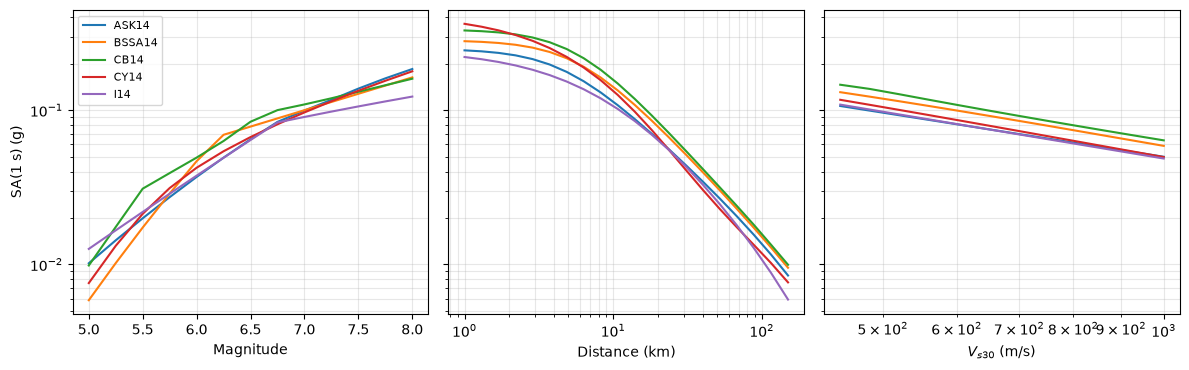

In [4]:
def sa(cls, period=1.0, **kwds):
    return cls(scenario.copy_with(**kwds)).interp_spec_accels([period])[0]


mags = np.linspace(5.0, 8.0, 13)
dists = np.geomspace(1.0, 150.0, 20)
vs30s = np.geomspace(450.0, 1000.0, 12)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for cls in classes:
    axes[0].plot(mags, [sa(cls, mag=m) for m in mags], label=cls.ABBREV)
    axes[1].plot(
        dists,
        [sa(cls, dist_rup=r, dist_jb=r, dist_x=r) for r in dists],
        label=cls.ABBREV,
    )
    axes[2].plot(vs30s, [sa(cls, v_s30=v) for v in vs30s], label=cls.ABBREV)
axes[0].set(xlabel="Magnitude", yscale="log", ylabel="SA(1 s) (g)")
axes[1].set(xlabel="Distance (km)", xscale="log", yscale="log")
axes[2].set(xlabel="$V_{s30}$ (m/s)", xscale="log", yscale="log")
for ax in axes:
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(fontsize=8)
fig.tight_layout()

### Observations

- **The medians agree at 1 s within about 15%** of each other for this scenario (0.064 g for Idriss to 0.084 g for Campbell and Bozorgnia), and the standard deviations are 0.68 to 0.72, with 0.79 for Idriss (2014).
- **Magnitude:** the models differ most below $M_w$ 6, by a factor of 2 at $M_w$ 5 (Boore et al. lowest, Idriss highest), and agree within about 15% from $M_w$ 6.5 to 8; Idriss (2014) has the flattest scaling above $M_w$ 7.
- **Distance:** the models cross near 20 km. Beyond that Idriss (2014) attenuates fastest and is the lowest at 150 km (0.006 g against 0.010 g for Campbell and Bozorgnia).
- **$V_{s30}$:** all models decrease at similar rates from 450 to 1000 m/s, the range for which all five are recommended, and differ by a constant factor.
- The models warn (`UserWarning`) when a scenario is outside the range of a model, which is why the plots stop at 150 km and 450 m/s.